# Giai đoạn 2 – Tự thu thập dữ liệu từ GOV.UK

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/23010216-hieusphamj/text-summarization-nlp/blob/main/notebooks/02_crawl_govuk.ipynb)

**Nguồn:** bài tin và thông cáo báo chí trên GOV.UK. Mỗi trang có trường `description` do biên tập viên viết, ta dùng làm **tóm tắt tham chiếu**, còn nội dung `details.body` là **bài gốc**.
**Giấy phép:** Open Government Licence v3.0 (xem `data/DATA_CARD.md`). Thu thập qua Content/Search API, nghỉ 0,5 giây giữa các request, có User-Agent định danh.

**Quy trình:** liệt kê bài theo (loại bài × tháng) → tải nội dung (có cache) → HTML sang văn bản → lọc chất lượng → khử trùng lặp → chia 80/10/10 → so sánh với CNN/DM.

> **Trước khi chạy:** mở `configs/data_govuk.yaml`, thay `THAY_EMAIL_CUA_BAN@example.com` trong `user_agent` bằng email thật của bạn rồi commit/push (hoặc sửa trực tiếp trên Colab).

In [3]:
# 0. Thiết lập môi trường
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/23010216-hieusphamj/text-summarization-nlp.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and not Path("src").exists() and not Path("text-summarization-nlp").exists():
    subprocess.run(["git", "clone", REPO_URL], check=True)
if Path("text-summarization-nlp").exists():
    os.chdir("text-summarization-nlp")
while not Path("src").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")
sys.path.insert(0, os.getcwd())

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt", "beautifulsoup4", "requests"], check=True)
    # Lưu cache dữ liệu thô lên Google Drive để không mất khi Colab ngắt kết nối
    from google.colab import drive
    drive.mount("/content/drive")
    drive_raw = Path("/content/drive/MyDrive/nlp_summarization/govuk_raw"); drive_raw.mkdir(parents=True, exist_ok=True)
    raw = Path("data/raw/govuk"); raw.parent.mkdir(parents=True, exist_ok=True)
    if not raw.exists():
        raw.symlink_to(drive_raw, target_is_directory=True)
print("Thư mục làm việc:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục làm việc: /content/text-summarization-nlp


In [4]:
# 1. Cấu hình chạy
CONFIG = "configs/data_govuk.yaml"
RUN_CRAWL = False      # False nếu đã crawl xong và chỉ muốn chạy lại phần làm sạch/EDA
MAX_DOCS = None        # chạy thử 300 bài trước; khi ổn đổi thành None để dùng max_docs trong config (6000)

import yaml
cfg = yaml.safe_load(open(CONFIG, encoding="utf-8"))
if RUN_CRAWL and "THAY_EMAIL" in cfg["user_agent"]:
    raise SystemExit("Hãy thay email thật vào user_agent trong configs/data_govuk.yaml rồi chạy lại.")

## 1. Kiểm tra nhanh API (smoke test)
In ra cấu trúc dữ liệu thật của vài bài để chắc các trường (`title`, `description`, `details.body`) đúng như kỳ vọng.

In [3]:
from src.crawl.govuk_crawler import main as crawl
if RUN_CRAWL:
    crawl(CONFIG, do_smoke=True)

robots.txt: /api/search.json -> cho phép
robots.txt: /api/content/ -> cho phép
[smoke] news_story ('2026-07-01', '2026-07-31'): 3 kết quả. Khóa trả về: ['_id', 'content_store_document_type', 'description', 'document_type', 'elasticsearch_type', 'es_score', 'index', 'link', 'public_timestamp', 'title']
- /government/news/first-phase-of-new-homes-delivered-for-military-families-in-cyprus
  title      : First phase of new homes delivered for military families in Cyprus
  description: Families are expected to move into the 46 new homes at Dhekelia Station soon.
  body[:150] : <div class="govspeak"><p>The first of 138 new homes for armed forces personnel and their families have been completed and handed over at Dhekelia Stat
- /government/news/criminal-bills-assessment-manual-cbam-and-supervisor-guidance
  title      : Criminal Bills Assessment Manual (CBAM) and Supervisor Guidance
  description: We have made a number of changes to the Criminal Bills Assessment Manual (CBAM) and Supervisor 

## 2. Thu thập dữ liệu thô
Cache từng bài vào `data/raw/govuk/` (trên Drive nếu dùng Colab). Có thể ngắt và chạy lại, bài đã tải sẽ được bỏ qua.

In [4]:
if RUN_CRAWL:
    crawl(CONFIG, max_docs=MAX_DOCS)
print("Số bài thô:", len(list(Path(cfg["raw_dir"]).glob("*.json"))))

robots.txt: /api/search.json -> cho phép
robots.txt: /api/content/ -> cho phép
Bước 1: liệt kê bài (3 loại × 45 tháng)
  news_story: +2686 bài
  press_release: +2693 bài
  government_response: +98 bài
Bước 2: tải nội dung 5477 bài (cache: data/raw/govuk)
  100/5477 (thành công 100, lỗi 0)
  200/5477 (thành công 200, lỗi 0)
  300/5477 (thành công 300, lỗi 0)
  400/5477 (thành công 400, lỗi 0)
  500/5477 (thành công 500, lỗi 0)
  600/5477 (thành công 600, lỗi 0)
  700/5477 (thành công 700, lỗi 0)
  800/5477 (thành công 800, lỗi 0)
  900/5477 (thành công 900, lỗi 0)
  1000/5477 (thành công 1000, lỗi 0)
  1100/5477 (thành công 1100, lỗi 0)
  1200/5477 (thành công 1200, lỗi 0)
  1300/5477 (thành công 1300, lỗi 0)
  1400/5477 (thành công 1400, lỗi 0)
  1500/5477 (thành công 1500, lỗi 0)
  1600/5477 (thành công 1600, lỗi 0)
  1700/5477 (thành công 1700, lỗi 0)
  1800/5477 (thành công 1800, lỗi 0)
  1900/5477 (thành công 1900, lỗi 0)
  2000/5477 (thành công 2000, lỗi 0)
  2100/5477 (thành công

## 3. Làm sạch, lọc, khử trùng lặp, chia tập

### 3.0 Chẩn đoán trước khi lọc
Xem dữ liệu thô bị loại ở bước nào và mức độ **tóm tắt chép lại một câu của bài** (overlap ≈ 1.0 nghĩa là `description` gần như là một câu trong bài).
Nếu tỉ lệ này cao, bộ dữ liệu quá dễ cho Lead-1/Lead-3 và đánh giá bị thổi phồng → ngưỡng `max_copy_overlap` (mặc định 0,9) sẽ loại các mẫu đó.

In [5]:
# 2b. (Colab) Chép cache dữ liệu thô từ Drive sang đĩa cục bộ để bước làm sạch đọc nhanh.
# Đọc hàng nghìn file nhỏ trực tiếp từ Drive mất >10 phút; chép song song chỉ mất khoảng 20 giây.
import time, subprocess
from pathlib import Path

link = Path("data/raw/govuk")
drive_src = Path("/content/drive/MyDrive/nlp_summarization/govuk_raw")

if IN_COLAB and link.is_symlink() and drive_src.exists():
    t0 = time.time()
    link.unlink()                                   # bỏ liên kết tới Drive
    link.mkdir(parents=True, exist_ok=True)
    subprocess.run(f"cd {drive_src} && ls | xargs -P 16 -I{{}} cp {{}} {link.resolve()}/", shell=True, check=True)
    print(f"Đã chép {len(list(link.glob('*.json')))} file về {link.resolve()} ({time.time() - t0:.0f}s)")
else:
    print("Bỏ qua: không chạy trên Colab hoặc cache đã nằm trên đĩa cục bộ.")

Thư mục đích: /content/text-summarization-nlp/data/raw/govuk
Số file JSON đã chép: 5477 | mất 17s


Số bản ghi thô: 5477
Bài < 80 từ: 172 | bài > 2500 từ: 66
Tóm tắt < 8 từ: 62 | tóm tắt > 80 từ: 0
Tóm tắt có >= 70% từ nằm trong MỘT câu của bài: 41.5%
Tóm tắt có >= 80% từ nằm trong MỘT câu của bài: 32.3%
Tóm tắt có >= 90% từ nằm trong MỘT câu của bài: 24.2%
Tóm tắt có >= 100% từ nằm trong MỘT câu của bài: 16.9%


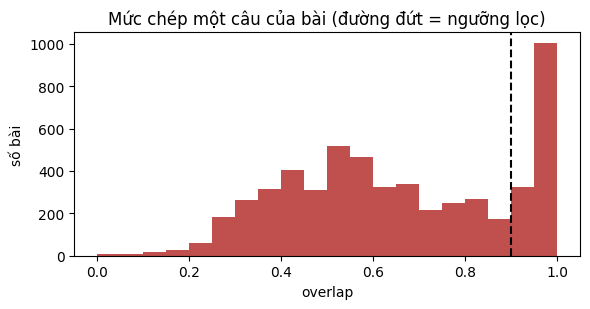

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import eda_utils as u
from src.crawl.build_dataset import load_raw
from src.crawl.clean import build_records

recs = build_records(load_raw(Path(cfg["raw_dir"])))
dg = pd.DataFrame({"art_w": [u.word_count(r["article"]) for r in recs],
                   "sum_w": [u.word_count(r["highlights"]) for r in recs],
                   "overlap": [u.max_sentence_overlap(r["article"], r["highlights"]) for r in recs]})
c = cfg["clean"]
print(f"Số bản ghi thô: {len(dg)}")
print(f"Bài < {c['min_article_words']} từ: {(dg.art_w < c['min_article_words']).sum()} | bài > {c['max_article_words']} từ: {(dg.art_w > c['max_article_words']).sum()}")
print(f"Tóm tắt < {c['min_summary_words']} từ: {(dg.sum_w < c['min_summary_words']).sum()} | tóm tắt > {c['max_summary_words']} từ: {(dg.sum_w > c['max_summary_words']).sum()}")
for t in (0.7, 0.8, 0.9, 1.0):
    print(f"Tóm tắt có >= {t:.0%} từ nằm trong MỘT câu của bài: {(dg.overlap >= t).mean()*100:.1f}%")
plt.figure(figsize=(6, 3.2)); plt.hist(dg.overlap, bins=20, color="#c0504d")
plt.axvline(c.get("max_copy_overlap", 0.9), ls="--", c="k"); plt.title("Mức chép một câu của bài (đường đứt = ngưỡng lọc)")
plt.xlabel("overlap"); plt.ylabel("số bài"); plt.tight_layout(); plt.show()

In [7]:
from src.crawl.build_dataset import main as build
splits = build(CONFIG)

                                        buoc  con_lai  bi_loai
                                  Bài tải về     5477        0
                      Có nội dung và tóm tắt     5475        2
                                Là tiếng Anh     5474        1
                           Độ dài bài hợp lệ     5238      236
                       Độ dài tóm tắt hợp lệ     5183       55
                            Tỉ lệ nén đủ lớn     5178        5
                        Tóm tắt khác tiêu đề     5165       13
           Tóm tắt không chép nguyên văn bài     4556      609
Tóm tắt không gần như chép một câu trong bài     3929      627
           Khử trùng lặp bài (600 ký tự đầu)     3917       12
                       Khử trùng lặp tóm tắt     3878       39
{'train': 3102, 'validation': 387, 'test': 389}


In [8]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import eda_utils as u
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("results/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("results/tables");  TAB.mkdir(parents=True, exist_ok=True)

### 3.1 Phễu làm sạch (bao nhiêu bài bị loại ở mỗi bước)

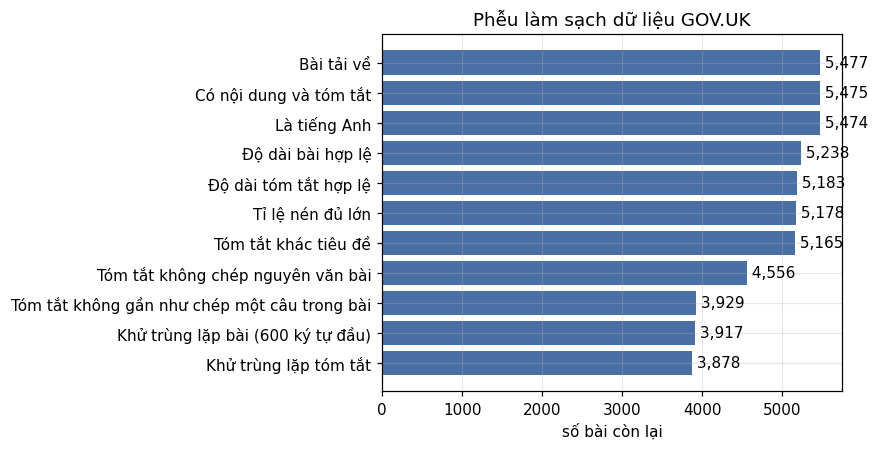

,buoc,con_lai,bi_loai
0,Bài tải về,5477,0
1,Có nội dung và tóm tắt,5475,2
2,Là tiếng Anh,5474,1
3,Độ dài bài hợp lệ,5238,236
4,Độ dài tóm tắt hợp lệ,5183,55
5,Tỉ lệ nén đủ lớn,5178,5
6,Tóm tắt khác tiêu đề,5165,13
7,Tóm tắt không chép nguyên văn bài,4556,609
8,Tóm tắt không gần như chép một câu trong bài,3929,627
9,Khử trùng lặp bài (600 ký tự đầu),3917,12


In [9]:
f = pd.read_csv(TAB / "govuk_cleaning_funnel.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(f["buoc"][::-1], f["con_lai"][::-1], color="#4a6fa5")
for i, v in enumerate(f["con_lai"][::-1]): ax.text(v, i, f" {v:,}", va="center")
ax.set_xlabel("số bài còn lại"); ax.set_title("Phễu làm sạch dữ liệu GOV.UK")
plt.tight_layout(); plt.savefig(FIG / "govuk_cleaning_funnel.png", dpi=200); plt.show()
f

## 4. EDA bộ dữ liệu tự thu thập

In [10]:
d = {s: pd.read_json(f"data/processed/govuk_{s}.jsonl", lines=True) for s in ["train", "validation", "test"]}
tr = d["train"].copy()
print({k: len(v) for k, v in d.items()})
tr["art_words"] = tr["article"].map(u.word_count); tr["sum_words"] = tr["highlights"].map(u.word_count)
tr["sum_sents"] = tr["highlights"].map(lambda t: len(u.split_sentences(t)))
tr["compression"] = [u.compression_ratio(a, s) for a, s in zip(tr["article"], tr["highlights"])]
display(tr["doc_type"].value_counts().rename("số bài").to_frame())
display(pd.DataFrame({"article_words": u.describe(tr["art_words"]), "summary_words": u.describe(tr["sum_words"]),
                      "summary_sentences": u.describe(tr["sum_sents"])}).round(1))

{'train': 3102, 'validation': 387, 'test': 389}


,số bài
doc_type,
news_story,1636
press_release,1400
government_response,66


,article_words,summary_words,summary_sentences
mean,645.5,21.3,1.0
std,422.3,7.0,0.2
min,80.0,8.0,1.0
p25,321.0,16.0,1.0
median,560.5,21.0,1.0
p75,867.0,25.0,1.0
p95,1453.9,34.0,1.0
max,2494.0,63.0,3.0


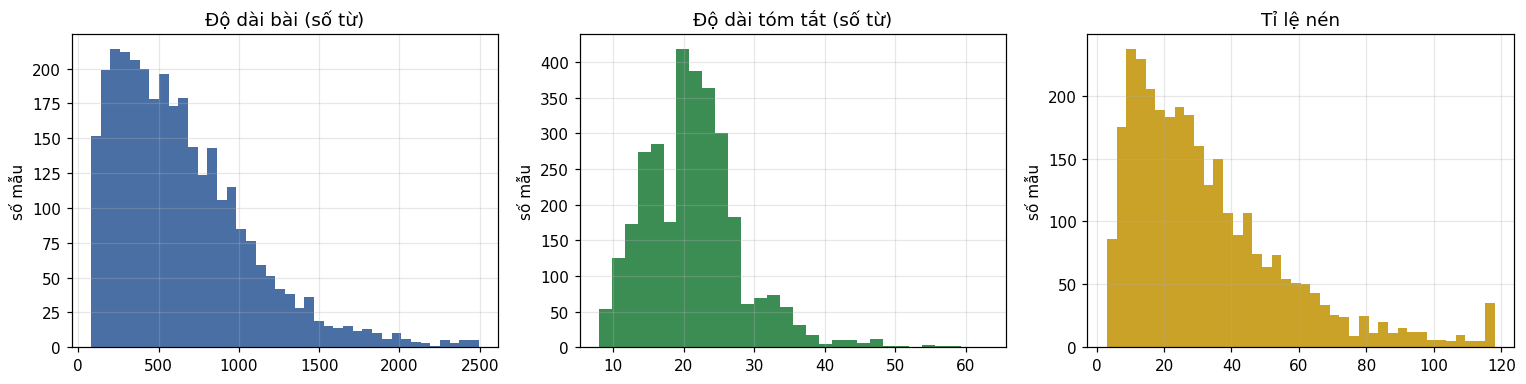

/tmp/ipykernel_9829/987642382.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  ym = pd.to_datetime(tr["date"], errors="coerce", utc=True).dt.to_period("Q").astype(str).value_counts().sort_index()


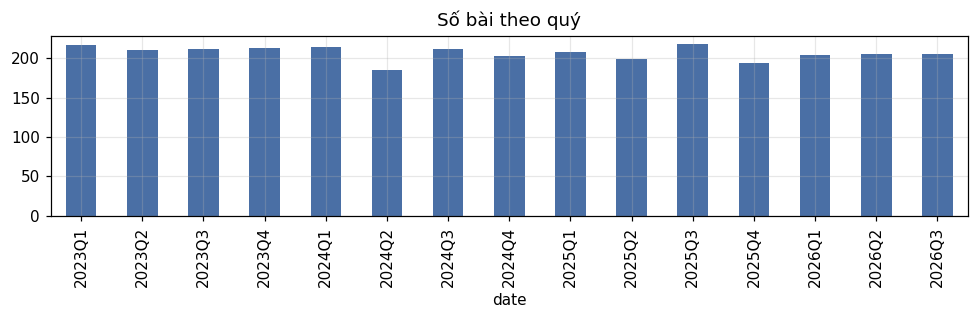

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(tr["art_words"], bins=40, color="#4a6fa5"); ax[0].set_title("Độ dài bài (số từ)")
ax[1].hist(tr["sum_words"], bins=30, color="#3c8d53"); ax[1].set_title("Độ dài tóm tắt (số từ)")
ax[2].hist(tr["compression"].clip(upper=tr["compression"].quantile(0.99)), bins=40, color="#c9a227"); ax[2].set_title("Tỉ lệ nén")
for a in ax: a.set_ylabel("số mẫu")
plt.tight_layout(); plt.savefig(FIG / "govuk_length_hist.png", dpi=200); plt.show()

ym = pd.to_datetime(tr["date"], errors="coerce", utc=True).dt.to_period("Q").astype(str).value_counts().sort_index()
ym.plot(kind="bar", figsize=(9, 3), color="#4a6fa5", title="Số bài theo quý"); plt.tight_layout()
plt.savefig(FIG / "govuk_by_quarter.png", dpi=200); plt.show()

In [12]:
N = min(3000, len(tr)); sub = tr.sample(N, random_state=42)
novel = {n: float(np.nanmean([u.novel_ngram_ratio(a, s, n) for a, s in zip(sub["article"], sub["highlights"])])) for n in (1, 2, 3)}
pos = np.array([p for a, h in zip(tr["article"].head(2000), tr["highlights"].head(2000)) for p in u.best_match_positions(a, h)])
within3, within10 = float((pos < 3).mean()), float((pos < 10).mean())
print({f"{k}-gram mới": f"{v*100:.1f}%" for k, v in novel.items()}, f"| 3 câu đầu: {within3*100:.1f}% | 10 câu đầu: {within10*100:.1f}%")

summary = pd.DataFrame([
    ("Số mẫu train/val/test", " / ".join(str(len(d[s])) for s in d)),
    ("Số từ bài – trung vị", round(tr["art_words"].median(), 1)),
    ("Số từ bài – p95", round(tr["art_words"].quantile(0.95), 1)),
    ("Số từ tóm tắt – trung vị", round(tr["sum_words"].median(), 1)),
    ("Số câu tóm tắt – trung bình", round(tr["sum_sents"].mean(), 2)),
    ("Tỉ lệ nén – trung vị (x)", round(tr["compression"].median(), 1)),
    ("% unigram mới", round(novel[1]*100, 1)), ("% bigram mới", round(novel[2]*100, 1)), ("% trigram mới", round(novel[3]*100, 1)),
    ("% câu tóm tắt có nguồn ở 3 câu đầu", round(within3*100, 1)),
    ("% câu tóm tắt có nguồn ở 10 câu đầu", round(within10*100, 1)),
], columns=["chỉ số", "GOV.UK"])
summary.to_csv(TAB / "govuk_eda_summary.csv", index=False)

{'1-gram mới': '19.0%', '2-gram mới': '56.0%', '3-gram mới': '74.1%'} | 3 câu đầu: 67.1% | 10 câu đầu: 87.6%


### 4.1 So sánh với CNN/DailyMail (dữ liệu huấn luyện chính)

In [13]:
cmp = summary.copy()
p = TAB / "cnn_dm_eda_summary.csv"
if p.exists():
    cnn = pd.read_csv(p).rename(columns={"giá trị": "CNN/DM"})
    cmp = cnn.merge(summary, on="chỉ số", how="right")[["chỉ số", "CNN/DM", "GOV.UK"]]
cmp.to_csv(TAB / "govuk_vs_cnn_dm.csv", index=False)
cmp

,chỉ số,CNN/DM,GOV.UK
0,Số mẫu train/val/test,NaN,3102 / 387 / 389
1,Số từ bài – trung vị,637.0,560.5
2,Số từ bài – p95,1353.0,1453.9
3,Số từ tóm tắt – trung vị,46.0,21.0
4,Số câu tóm tắt – trung bình,3.8,1.04
5,Tỉ lệ nén – trung vị (x),13.6,26.9
6,% unigram mới,13.0,19.0
7,% bigram mới,52.2,56.0
8,% trigram mới,71.7,74.1
9,% câu tóm tắt có nguồn ở 3 câu đầu,25.6,67.1


## 5. Xem ngẫu nhiên vài mẫu (kiểm tra chất lượng bằng mắt)

In [14]:
for _, r in tr.sample(min(4, len(tr)), random_state=3).iterrows():
    print(f"[{r['doc_type']}] {r['title']}")
    print("  TÓM TẮT:", r["highlights"])
    print("  BÀI    :", r["article"][:300].replace("\n", " "), "...\n")

[news_story] MOD showcases integrated wargaming expertise at NATO’s Premier Concept Development Conference
  TÓM TẮT: Cyber & Specialist Operations Command’s (CSOC) Integrated Warfare Centre (IWC) and Dstl have underscored Britain’s leading role in modern defence analytical wargaming.
  BÀI    : This year’s Concept Development plus Wargaming Initiative for NATO Conference (CD & WIN 2025) helped to share fresh insights from concept development and wargaming, strengthen collaborative networks across NATO, and bring partners together to explore common challenges, exchange best practice, and ad ...

[press_release] HMS Duncan deploys to the Red Sea to protect shipping routes
  TÓM TẮT: The Type 45 destroyed sailed from Portsmouth today to relieve her sister ship, HMS Diamond
  BÀI    : Royal Navy warship HMS Duncan has deployed from Portsmouth today to the Red Sea. The Type 45 destroyer will relieve its sister ship HMS Diamond, which has been protecting shipping lanes in the Red Sea from H

## 6. Nhận xét (điền sau khi chạy với MAX_DOCS đầy đủ, rồi chép vào `docs/decisions.md` mục D3)

- **Quy mô:** 5.477 bài thô (2023-01 → 2026-09), không bài nào lỗi sau khi tải; còn 3.878 cặp sau làm sạch (70,8%), chia train/val/test = 3.102 / 387 / 389. Loại bài: news_story 1.636, press_release 1.400, government_response 66 (tập train).
- **Phễu làm sạch:** bước loại nhiều nhất là tóm tắt chép lại bài: 609 bài chép nguyên văn và 627 bài gần như chép một câu (overlap từ ≥ 0,9), cộng 1.236 bài (22,6% số bài thô). Tiếp theo là độ dài bài không hợp lệ (236 bài) và độ dài tóm tắt (55 bài). Khử trùng lặp loại 51 bài.
- **Ngưỡng lọc 0,9:** được chọn sau khi xem phân bố trên mẫu thử 300 bài (overlap ≥ 0,7 / 0,8 / 0,9 / 1,0 lần lượt chiếm 42,7% / 31,3% / 21,0% / 14,3%), tức ngưỡng được đặt sau khi quan sát dữ liệu. Tỉ lệ bài bị loại ở bước này trên toàn bộ (13,8%) khớp với trên mẫu thử (13,5%).
- **Độ dài:** bài trung vị 560,5 từ (p95 = 1.453,9), tóm tắt trung vị 21 từ (p95 = 34, max = 63), 1,04 câu tóm tắt; tỉ lệ nén 26,9 lần (CNN/DM: 637 từ, 46 từ, 3,8 câu, 13,6 lần).
- **n-gram mới:** 19,0% unigram, 56,0% bigram, 74,1% trigram (CNN/DM: 13,0 / 52,2 / 71,7). Không so sánh trực tiếp được vì ta đã lọc bỏ các tóm tắt gần như chép một câu và tóm tắt GOV.UK ngắn hơn.
- **Lead bias:** 67,1% câu tóm tắt có nguồn ở 3 câu đầu và 87,6% ở 10 câu đầu (CNN/DM: 25,6% và 64,0%).
- **Hệ quả cho các giai đoạn sau:**
  - Lead-1 / Lead-3 dự kiến là baseline mạnh trên bộ này (kiểm chứng ở GĐ4).
  - `max_target = 64` cho GOV.UK (tóm tắt dài nhất 63 từ). Cắt đầu vào 512 token ít gây mất thông tin hơn ở CNN/DM.
  - Mô hình huấn luyện trên CNN/DM sinh tóm tắt dài hơn nhiều so với tham chiếu GOV.UK → báo cáo kèm độ dài tóm tắt và bổ sung thí nghiệm fine-tune trên train GOV.UK.
  - Tập test chỉ 389 mẫu → dùng bootstrap để tính khoảng tin cậy ở GĐ7.
- **Đánh đổi:** tóm tắt chỉ một câu và miền hẹp (thông tin chính phủ Anh); `description` do biên tập viên viết cho trang web, chưa được người kiểm định chất lượng nhãn (sẽ chấm tay mẫu nhỏ ở GĐ7).

In [15]:
# 7. (Colab) Đóng gói kết quả để tải về và commit vào repo
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("phase2_outputs", "zip", ".", "results")
    shutil.copy("data/samples/govuk_sample.jsonl", "govuk_sample.jsonl")
    files.download("phase2_outputs.zip"); files.download("govuk_sample.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>